# Data Integration and PCA

In [18]:
import numpy as np
import pandas as pd
import geopandas as gpd
from sklearn.preprocessing import StandardScaler

from sklearn.decomposition import PCA

import matplotlib.pyplot as plt
import matplotlib
import seaborn as sns

from pathlib import Path

import warnings
warnings.filterwarnings(action = 'ignore')

In [19]:
acs = pd.read_csv("ACS_5-Year_Economic_Characteristics_DC_Census_Tract.csv") 
acs.head()

,OBJECTID,STATEFP,COUNTYFP,TRACTCE,GEOID,GEOIDFQ,NAME,NAMELSAD,MTFCC,FUNCSTAT,...,DP03_0132PE,DP03_0133PE,DP03_0134PE,DP03_0135PE,DP03_0136PE,DP03_0137PE,SE_ANNO_CAD_DATA,GLOBALID,SHAPEAREA,SHAPELEN
0,1,11,1,5302,11001005302,1400000US11001005302,53.02,Census Tract 53.02,G5020,S,...,0.0,1.5,1.1,3.9,2.0,1.6,NaN,{8D441CA5-6D45-438E-A5F2-61AC35F36BA0},0,0
1,2,11,1,4402,11001004402,1400000US11001004402,44.02,Census Tract 44.02,G5020,S,...,54.4,7.2,5.3,25.4,9.7,8.0,NaN,{1C63F779-6D51-4833-9398-C0EAAD6A134C},0,0
2,3,11,1,10602,11001010602,1400000US11001010602,106.02,Census Tract 106.02,G5020,S,...,41.3,12.4,11.6,22.2,12.4,15.4,NaN,{B68F4A9D-7AD5-4265-A56C-C8DB9F04A596},0,0
3,4,11,1,804,11001000804,1400000US11001000804,8.04,Census Tract 8.04,G5020,S,...,0.0,3.6,2.3,7.7,1.0,10.7,NaN,{91534B3F-F409-4BF1-B676-DB8D9B5CD13E},0,0
4,5,11,1,3902,11001003902,1400000US11001003902,39.02,Census Tract 39.02,G5020,S,...,0.0,6.7,3.1,27.7,0.0,10.2,NaN,{A633B310-4F16-473E-88B3-F09B4F323DE6},0,0


### Counting crime points in each census tract and adding those points on a polygon data using spatial join. 
#### The next codes have been adopted from DC_Crime_CensusTract_SpatialJoin.ipynb by Professor Park

In [20]:
tracts = gpd.read_file('Census_Tracts_in_2020.shp')
tracts = tracts[['GEOID', 'TRACT', 'NAME', 'geometry']].copy()
tracts = tracts.to_crs('EPSG:4326')

tracts.head()

,GEOID,TRACT,NAME,geometry
0,11001002002,002002,Census Tract 20.02,"POLYGON ((-77.03642 38.94975, -77.03642 38.950..."
1,11001002101,002101,Census Tract 21.01,"POLYGON ((-77.02824 38.95813, -77.02824 38.958..."
2,11001002102,002102,Census Tract 21.02,"POLYGON ((-77.01997 38.95819, -77.01997 38.958..."
3,11001002201,002201,Census Tract 22.01,"POLYGON ((-77.02743 38.95188, -77.02727 38.951..."
4,11001002202,002202,Census Tract 22.02,"POLYGON ((-77.01968 38.95209, -77.01958 38.952..."


In [21]:
crime = pd.read_csv("./Crime_Incidents_in_2025.csv")
crime = crime.dropna(subset=['LONGITUDE', 'LATITUDE'])

crime[['OFFENSE', 'LONGITUDE', 'LATITUDE']].head()

,OFFENSE,LONGITUDE,LATITUDE
0,HOMICIDE,-76.934478,38.888528
1,HOMICIDE,-76.993222,38.833020
2,HOMICIDE,-77.000574,38.842411
3,HOMICIDE,-76.921301,38.892670
4,MOTOR VEHICLE THEFT,-76.950398,38.863721


<Axes: >

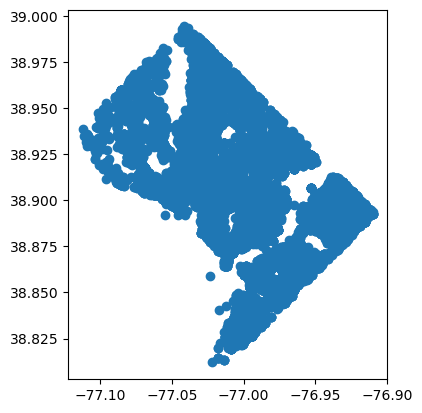

In [22]:
crime_points = gpd.GeoDataFrame(
    crime,
    geometry=gpd.points_from_xy(crime['LONGITUDE'], crime['LATITUDE']),
    crs='EPSG:4326'
)
crime_points.plot()

In [23]:
joined = gpd.sjoin(
    crime_points,
    tracts[['GEOID', 'geometry']],
    how='inner',
    predicate='within'
)

joined[['OFFENSE', 'GEOID']].head()

,OFFENSE,GEOID
0,HOMICIDE,11001009906
1,HOMICIDE,11001009801
2,HOMICIDE,11001009804
3,HOMICIDE,11001007808
4,MOTOR VEHICLE THEFT,11001007603


In [24]:
crime_counts = joined.groupby('GEOID').size()
crime_counts = crime_counts.reset_index(name='crime_n')

tracts_with_crime = tracts.merge(crime_counts, on='GEOID', how='left')
tracts_with_crime['crime_n'] = tracts_with_crime['crime_n'].fillna(0).astype(int)

tracts_with_crime[['GEOID', 'NAME', 'crime_n']].head()

,GEOID,NAME,crime_n
0,11001002002,Census Tract 20.02,85
1,11001002101,Census Tract 21.01,174
2,11001002102,Census Tract 21.02,104
3,11001002201,Census Tract 22.01,54
4,11001002202,Census Tract 22.02,78


In [25]:
offense_counts = pd.crosstab(
    joined['GEOID'],
    joined['OFFENSE'].fillna('UNKNOWN')
)

offense_counts.head()

OFFENSE,ARSON,ASSAULT W/DANGEROUS WEAPON,BURGLARY,HOMICIDE,MOTOR VEHICLE THEFT,ROBBERY,SEX ABUSE,THEFT F/AUTO,THEFT/OTHER
GEOID,,,,,,,,,
11001000101,0,0,0,0,1,1,0,5,11
11001000102,0,0,1,0,17,1,1,64,164
11001000201,0,0,1,0,1,0,0,2,8
11001000202,0,3,3,0,9,1,0,96,230
11001000300,0,2,1,0,3,2,0,8,47


In [26]:
offense_counts = offense_counts.rename(columns={
    'ARSON': 'arson_n',
    'ASSAULT W/DANGEROUS WEAPON': 'assault_n',
    'BURGLARY': 'burglary_n',
    'HOMICIDE': 'homicide_n',
    'MOTOR VEHICLE THEFT': 'mv_theft_n',
    'ROBBERY': 'robbery_n',
    'SEX ABUSE': 'sexabuse_n',
    'THEFT F/AUTO': 'theftcar_n',
    'THEFT/OTHER': 'theftoth_n',
    'UNKNOWN': 'unknown_n'
})

# Keep this list to select all offense-count columns together.
offense_columns = offense_counts.columns.tolist()
offense_counts = offense_counts.reset_index()

offense_counts.head()

OFFENSE,GEOID,arson_n,assault_n,burglary_n,homicide_n,mv_theft_n,robbery_n,sexabuse_n,theftcar_n,theftoth_n
0,11001000101,0,0,0,0,1,1,0,5,11
1,11001000102,0,0,1,0,17,1,1,64,164
2,11001000201,0,0,1,0,1,0,0,2,8
3,11001000202,0,3,3,0,9,1,0,96,230
4,11001000300,0,2,1,0,3,2,0,8,47


In [27]:
tracts_with_crime = tracts_with_crime.merge(
    offense_counts,
    on='GEOID',
    how='left'
)

tracts_with_crime[offense_columns] = (
    tracts_with_crime[offense_columns].fillna(0).astype(int)
)

tracts_with_crime.drop(columns=['geometry']).head()

,GEOID,TRACT,NAME,crime_n,arson_n,assault_n,burglary_n,homicide_n,mv_theft_n,robbery_n,sexabuse_n,theftcar_n,theftoth_n
0,11001002002,002002,Census Tract 20.02,85,0,6,2,0,26,6,0,20,25
1,11001002101,002101,Census Tract 21.01,174,0,11,11,0,28,9,0,28,87
2,11001002102,002102,Census Tract 21.02,104,0,6,2,0,32,3,0,36,25
3,11001002201,002201,Census Tract 22.01,54,0,1,0,0,16,4,0,14,19
4,11001002202,002202,Census Tract 22.02,78,0,6,0,0,28,2,1,17,24


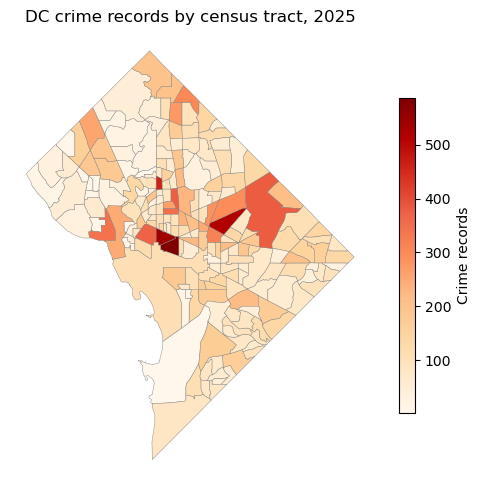

In [28]:
fig, ax = plt.subplots(figsize=(6, 5))

tracts_with_crime.plot(
    column='crime_n',
    cmap='OrRd',
    edgecolor='grey',
    linewidth=0.3,
    legend=True,
    legend_kwds={'label': 'Crime records', 'shrink': 0.7},
    ax=ax
)

ax.set_title('DC crime records by census tract, 2025')
ax.set_axis_off()
plt.tight_layout()
plt.show()

In [29]:
output_folder = Path('output/simple_4326')
output_folder.mkdir(parents=True, exist_ok=True)

tracts_with_crime.to_file(
    output_folder / 'dc_tracts_crime_2025.shp',
    driver='ESRI Shapefile',
    index=False
)

tracts_with_crime.drop(columns=['geometry']).to_csv(
    output_folder / 'dc_tract_crime_counts_2025.csv',
    index=False
)

### From here, merging the supplementary dataset with tracts_with_crime.
#### One issue that kept coming up was that the data woud not merge on GEOID due to tracts['GEOID'] being a string and acs['GEOID'] being an integer. Hence, converging acs['GEOID'] to a string to match tracts['GEOID'] here: 

In [30]:
acs['GEOID'] = acs['GEOID'].astype(str)

#### Then merge acs dataset with tracts_with_crime dataset. The connecting identifier is 'GEOID'.

In [31]:
dc = tracts_with_crime.merge(acs, on='GEOID', how='left', suffixes=('', '_acs'))
dc.head()

,GEOID,TRACT,NAME,geometry,crime_n,arson_n,assault_n,burglary_n,homicide_n,mv_theft_n,...,DP03_0132PE,DP03_0133PE,DP03_0134PE,DP03_0135PE,DP03_0136PE,DP03_0137PE,SE_ANNO_CAD_DATA,GLOBALID,SHAPEAREA,SHAPELEN
0,11001002002,002002,Census Tract 20.02,"POLYGON ((-77.03642 38.94975, -77.03642 38.950...",85,0,6,2,0,26,...,0.0,6.8,6.9,6.3,4.6,8.1,NaN,{A6F5F313-DE0B-47D9-96D0-FC1337BF288C},0,0
1,11001002101,002101,Census Tract 21.01,"POLYGON ((-77.02824 38.95813, -77.02824 38.958...",174,0,11,11,0,28,...,2.6,6.5,5.3,12.5,4.0,7.8,NaN,{E6D4A023-9C0F-432E-BC5F-A2A7FEF89C02},0,0
2,11001002102,002102,Census Tract 21.02,"POLYGON ((-77.01997 38.95819, -77.01997 38.958...",104,0,6,2,0,32,...,3.0,14.1,15.0,9.1,3.7,32.4,NaN,{79FBE5B5-3641-45D3-ACB2-E8767E0FE148},0,0
3,11001002201,002201,Census Tract 22.01,"POLYGON ((-77.02743 38.95188, -77.02727 38.951...",54,0,1,0,0,16,...,0.0,1.2,0.6,4.0,0.0,4.5,NaN,{27CBE22E-F304-4643-8E5E-8615C12E7688},0,0
4,11001002202,002202,Census Tract 22.02,"POLYGON ((-77.01968 38.95209, -77.01958 38.952...",78,0,6,0,0,28,...,54.2,11.5,11.6,11.1,27.9,13.4,NaN,{8D46BB44-2F84-46A0-A5F1-2F69E7AD5BA6},0,0


#### Renamed relevant variables for convinience.

In [32]:
dc = dc.rename(columns={'DP03_0001E':  'employment', 'DP03_0063E':  'mean_income', 'DP03_0133PE': 'povertylvl'})
dc.head()

,GEOID,TRACT,NAME,geometry,crime_n,arson_n,assault_n,burglary_n,homicide_n,mv_theft_n,...,DP03_0132PE,povertylvl,DP03_0134PE,DP03_0135PE,DP03_0136PE,DP03_0137PE,SE_ANNO_CAD_DATA,GLOBALID,SHAPEAREA,SHAPELEN
0,11001002002,002002,Census Tract 20.02,"POLYGON ((-77.03642 38.94975, -77.03642 38.950...",85,0,6,2,0,26,...,0.0,6.8,6.9,6.3,4.6,8.1,NaN,{A6F5F313-DE0B-47D9-96D0-FC1337BF288C},0,0
1,11001002101,002101,Census Tract 21.01,"POLYGON ((-77.02824 38.95813, -77.02824 38.958...",174,0,11,11,0,28,...,2.6,6.5,5.3,12.5,4.0,7.8,NaN,{E6D4A023-9C0F-432E-BC5F-A2A7FEF89C02},0,0
2,11001002102,002102,Census Tract 21.02,"POLYGON ((-77.01997 38.95819, -77.01997 38.958...",104,0,6,2,0,32,...,3.0,14.1,15.0,9.1,3.7,32.4,NaN,{79FBE5B5-3641-45D3-ACB2-E8767E0FE148},0,0
3,11001002201,002201,Census Tract 22.01,"POLYGON ((-77.02743 38.95188, -77.02727 38.951...",54,0,1,0,0,16,...,0.0,1.2,0.6,4.0,0.0,4.5,NaN,{27CBE22E-F304-4643-8E5E-8615C12E7688},0,0
4,11001002202,002202,Census Tract 22.02,"POLYGON ((-77.01968 38.95209, -77.01958 38.952...",78,0,6,0,0,28,...,54.2,11.5,11.6,11.1,27.9,13.4,NaN,{8D46BB44-2F84-46A0-A5F1-2F69E7AD5BA6},0,0


#### Checking if there is any row or missing value in the merged dataset dc, and if the 'GEOID' column is unique.

In [33]:
print("tracts:", len(tracts), "merged _rows:", len(dc)) # should match the numebr
for col in ['employment', 'mean_income', 'povertylvl']:
    print(col, "missing:", dc[col].isna().sum())
print("GEOID unique:", dc['GEOID'].is_unique)

tracts: 206 merged _rows: 206
employment missing: 0
mean_income missing: 0
povertylvl missing: 0
GEOID unique: True


#### Created two new columns, grouping crimes into two categories: violent crimes and property crimes

In [34]:
dc['violent_n']  = dc[['homicide_n', 'robbery_n', 'assault_n', 'sexabuse_n']].sum(axis=1)
dc['property_n'] = dc[['burglary_n', 'mv_theft_n', 'theftcar_n', 'theftoth_n']].sum(axis=1)
dc.head()

,GEOID,TRACT,NAME,geometry,crime_n,arson_n,assault_n,burglary_n,homicide_n,mv_theft_n,...,DP03_0134PE,DP03_0135PE,DP03_0136PE,DP03_0137PE,SE_ANNO_CAD_DATA,GLOBALID,SHAPEAREA,SHAPELEN,violent_n,property_n
0,11001002002,002002,Census Tract 20.02,"POLYGON ((-77.03642 38.94975, -77.03642 38.950...",85,0,6,2,0,26,...,6.9,6.3,4.6,8.1,NaN,{A6F5F313-DE0B-47D9-96D0-FC1337BF288C},0,0,12,73
1,11001002101,002101,Census Tract 21.01,"POLYGON ((-77.02824 38.95813, -77.02824 38.958...",174,0,11,11,0,28,...,5.3,12.5,4.0,7.8,NaN,{E6D4A023-9C0F-432E-BC5F-A2A7FEF89C02},0,0,20,154
2,11001002102,002102,Census Tract 21.02,"POLYGON ((-77.01997 38.95819, -77.01997 38.958...",104,0,6,2,0,32,...,15.0,9.1,3.7,32.4,NaN,{79FBE5B5-3641-45D3-ACB2-E8767E0FE148},0,0,9,95
3,11001002201,002201,Census Tract 22.01,"POLYGON ((-77.02743 38.95188, -77.02727 38.951...",54,0,1,0,0,16,...,0.6,4.0,0.0,4.5,NaN,{27CBE22E-F304-4643-8E5E-8615C12E7688},0,0,5,49
4,11001002202,002202,Census Tract 22.02,"POLYGON ((-77.01968 38.95209, -77.01958 38.952...",78,0,6,0,0,28,...,11.6,11.1,27.9,13.4,NaN,{8D46BB44-2F84-46A0-A5F1-2F69E7AD5BA6},0,0,9,69


#### The suitable varaibles we chose for PCA are: violent crime rate, property crime rate, mean household income, and poverty level. Since the datasets have been merged into one on GEOID, two categorized crime rates and socioeconomic characterstics are the relevant variables to find the patterns across areas. Variables for identification are only for labeling instances, therefore, excluded. Other income measures or employment measures have been excluded as well since they are highly correlated with the selected variables. Categorical variables with no numerical values have also been disregarded as they are not suitable for PCA

#### The variables that need standardization are: violent_n. property_n, mean_income, and 'povertylvl'. Because the units of these variables vary from tens to tens of thousands, it is hard to see the true pattern of the data. PCA needs sizes of variance to effectively handle dimensions, using directions.

In [35]:
from sklearn.preprocessing import StandardScaler
dc_st = StandardScaler().fit_transform(dc[['violent_n', 'property_n', 'mean_income', 'povertylvl']])
dc_st = pd.DataFrame(dc_st, columns = ['violent_n', 'property_n', 'mean_income', 'povertylvl'])
dc_st.head(10)

,violent_n,property_n,mean_income,povertylvl
0,0.000449,-0.350232,0.668944,-0.611793
1,0.740957,0.543752,-0.218589,-0.633510
2,-0.277241,-0.107422,-0.283575,-0.083353
3,-0.647495,-0.615116,0.415868,-1.017172
4,-0.277241,-0.394379,-0.488642,-0.271564
5,-1.017748,-0.968295,0.721654,-0.966499
6,-0.925185,1.559140,1.340339,-0.705899
7,-1.110312,-1.023479,-1.952235,6.134868
8,-0.740058,2.574529,1.333714,-0.076114
9,-0.740058,-0.504748,1.201890,-0.713138


## PCA

In [36]:
pca = PCA(random_state = 2000, n_components = None)
pca.fit_transform(dc_st)

array([[ 8.16860949e-01,  1.44385738e-01, -4.04934963e-01,
         3.03904929e-01],
       [-2.70619672e-01,  9.31349701e-01, -5.34817917e-01,
        -2.59076590e-01],
       [ 3.74921719e-02, -2.50251392e-01, -1.43112654e-02,
        -3.33958421e-01],
       [ 1.27656745e+00, -2.61742854e-01, -4.80456973e-01,
        -2.76095279e-01],
       [ 6.88910459e-02, -4.51851163e-01, -3.25811155e-01,
        -4.79424520e-01],
       [ 1.69598688e+00, -6.35572746e-01, -3.70853244e-01,
        -1.02251980e-01],
       [ 1.41917981e+00,  1.39861560e+00,  1.24524531e+00,
        -2.46688861e-01],
       [-3.85123947e+00, -4.13879084e+00,  3.23059861e+00,
         1.15313412e+00],
       [ 7.80279647e-01,  2.01424771e+00,  2.06421014e+00,
        -1.82974175e-01],
       [ 1.61915338e+00, -1.26067973e-01, -1.99858026e-02,
         3.42944704e-01],
       [ 1.44286611e+00, -7.37545347e-01,  4.79765148e-01,
         1.14767555e+00],
       [ 7.28891915e-01, -3.85911144e-02,  4.57058988e-01,
      

### Variance or eigenvalues

In [39]:
print(pca.explained_variance_)
print(pca.explained_variance_ratio_)
exp_variance_ratio = pca.explained_variance_ratio_
print(exp_variance_ratio)

[1.88172546 1.33501113 0.45216522 0.35061039]
[0.46814772 0.33213262 0.11249256 0.0872271 ]
[0.46814772 0.33213262 0.11249256 0.0872271 ]


#### Screeplot

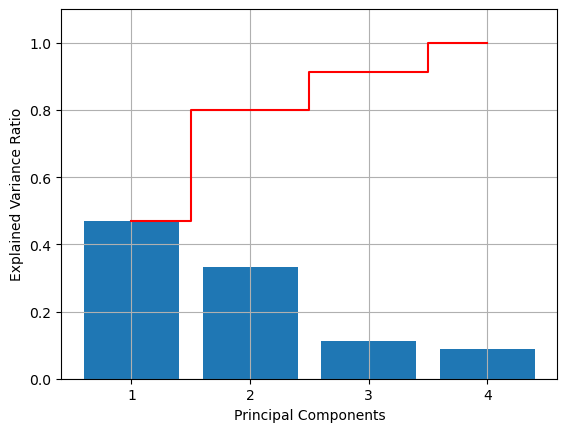

In [40]:
def explained_variance_ratio_plot(exp_variance_ratio):
    x_axis = range(1, len(exp_variance_ratio)+1)
    plt.bar(x_axis, exp_variance_ratio,
            align = 'center', label = 'Individual Explained Variance Ratio')
    plt.step(x_axis, np.cumsum(exp_variance_ratio),
             where = 'mid', color='red', label='Cumulative Explained Variance Ratio')
    plt.ylim(0, 1.1)
    plt.xticks(x_axis)
    plt.xlabel('Principal Components')
    plt.ylabel('Explained Variance Ratio')
    plt.grid()
    plt.show()
   
explained_variance_ratio_plot(exp_variance_ratio)

#### The scree plot drops after principal component 2. The first two components reach 80% of variance with eigenvalues of above 1. This means they explain more variance than a single variance would. Therefore, we are preserving two components

### Loadings or eigenvectors

In [54]:
loadings = pca.components_
print(loadings.shape, len(dc.columns))

(4, 4) 170


In [56]:
loadings = pca.components_.transpose() * np.sqrt(pca.explained_variance_)

pc_list = [f"PC{i}" for i in range(1, pca.components_.shape[0] + 1)]
loadings_df = pd.DataFrame(loadings, columns=pc_list, index=pca.feature_names_in_) # pca.feature_names_in to match the 4 rows of loadings.
loadings_df.index.name = "variable"
loadings_df

,PC1,PC2,PC3,PC4
variable,,,,
violent_n,-0.721469,0.519651,-0.375199,0.271200
property_n,-0.251571,0.881103,0.367406,-0.173953
mean_income,0.844164,0.307354,0.145799,0.420168
povertylvl,-0.765054,-0.440642,0.393886,0.265066


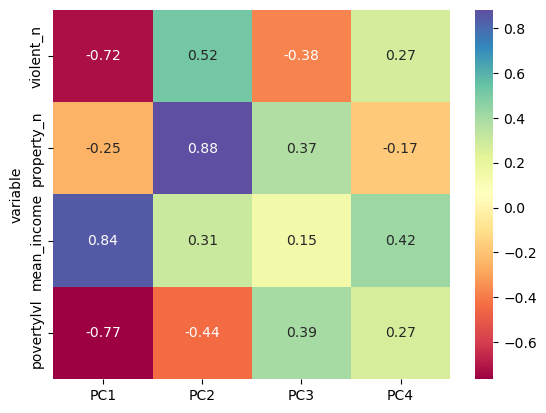

In [57]:
ax = sns.heatmap(loadings_df, annot=True, cmap='Spectral')
plt.show()

#### According to the heatmap, income loads strongly positive whereas violent crime and poverty are strongly negative for PC1. PC2 is mostly property crime which doesn't show much connection with other variables, hence independent. PC3 and PC4 doesn't show a notable pattern which supports our decision of preserving PC1 and PC2

### Projected data or scores

In [69]:
pca.transform(dc_st)
scores = pca.transform(dc_st).transpose()
num_pc = pca.components_.shape[1]
pc_list = ["PC"+ str(i) for i in list(range(1, num_pc+1))]
scores_df = pd.DataFrame.from_dict(dict(zip(pc_list, scores)))
scores_df['dc'] = dc.index
scores_df = scores_df.set_index('dc')
scores_df

,PC1,PC2,PC3,PC4
dc,,,,
0,0.816861,0.144386,-0.404935,0.303905
1,-0.270620,0.931350,-0.534818,-0.259077
2,0.037492,-0.250251,-0.014311,-0.333958
3,1.276567,-0.261743,-0.480457,-0.276095
4,0.068891,-0.451851,-0.325811,-0.479425
...,...,...,...,...
201,-1.776912,-0.713380,-0.362716,0.038032
202,0.595582,-1.099930,-0.308744,-0.430027
203,1.024574,-0.882981,-0.355531,-0.409539


In [63]:
scores_df.sort_values(by=['PC1'],ascending=False).head(10)

,PC1,PC2,PC3,PC4
dc,,,,
19,3.702096,0.530237,0.661517,2.314306
22,3.562220,0.177604,0.755357,2.412176
33,3.302265,0.287167,0.421652,1.599544
21,2.717634,0.113133,0.816783,1.984659
20,2.425779,-0.376571,-0.033103,0.892916
31,2.348515,-0.374197,0.186415,0.867190
47,2.257952,-0.356915,0.096280,0.838516
24,2.160891,-0.588426,0.042888,0.687250
13,2.079428,0.984330,1.002025,0.217797


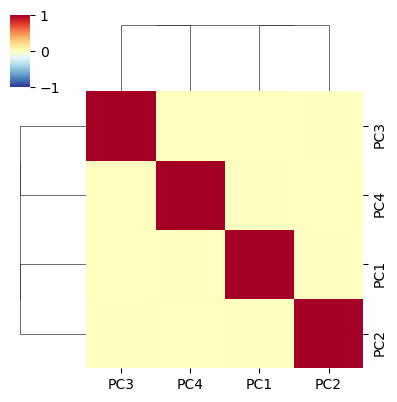

In [64]:
cor = scores_df.corr()
sns.clustermap(cor, annot = False, cmap = 'RdYlBu_r',vmin = -1, vmax = 1,figsize=(4,4),)

#### The clustermap above that demonstrates correlation between the principal components scores, shows an orthogonal pattern of principal components. This confirms the principal components capture separate variation in the data

In [75]:
cols = [pca.feature_names_in_[i] for i in range(pca.n_components_)]  # your real column names
X = dc[cols].dropna()          # 'merged' = your merged dataframe

X_scaled = pd.DataFrame(StandardScaler().fit_transform(X), columns=cols, index=X.index)
pca = PCA().fit(X_scaled)

In [76]:
# biplot: https://sukhbinder.wordpress.com/2015/08/05/biplot-with-python/
def biplot(score, coeff, pcax, pcay, labels=None):
  pca1 = pcax - 1
  pca2 = pcay - 1
    
  xs = score[:,pca1]
  ys = score[:,pca2]
    
  scalex = 1.0/(xs.max()- xs.min())
  scaley = 1.0/(ys.max()- ys.min())
    
  plt.figure(figsize=(8, 6))  
  plt.scatter(xs*scalex, ys*scaley, alpha = 0.5)

  n = coeff.shape[0]
  for i in range(n):
    plt.arrow(0, 0, coeff[i,pca1], coeff[i,pca2],color='r',alpha=0.5)
    if labels is None:
      plt.text(coeff[i,pca1]* 1.15, coeff[i,pca2] * 1.15, "Var"+str(i+1), color='g', ha='center', va='center')
    else:
      plt.text(coeff[i,pca1]* 1.15, coeff[i,pca2] * 1.15, labels[i], color='g', ha='center', va='center')
  plt.xlim(-1,1)
  plt.ylim(-1,1)
    
  plt.xlabel(f"PC{pcax} ({pca.explained_variance_ratio_[pca1]*100:.2f} %)")
  plt.ylabel(f"PC{pcay} ({pca.explained_variance_ratio_[pca2]*100:.2f} %)")
  plt.grid()

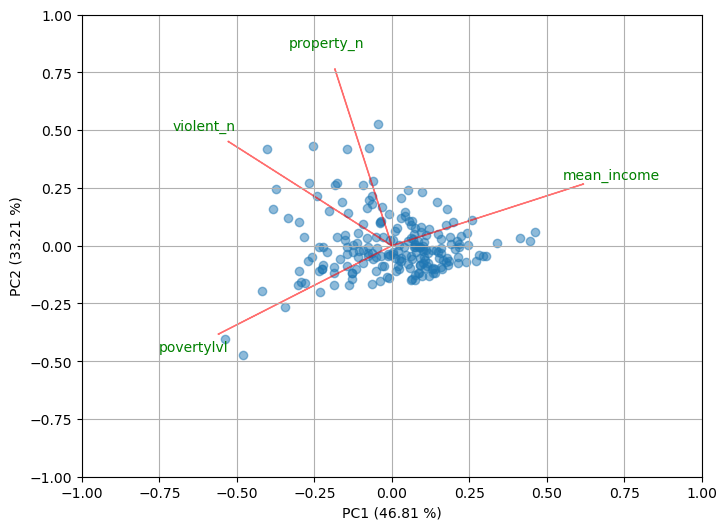

In [79]:
score = pca.transform(X_scaled)
coeff = pca.components_.transpose()
labels = X_scaled.columns 

biplot(score, coeff, 1, 2, labels=labels)
plt.show()

#### In the displayed biplot, mean_income points towards the right while povertylvl points to the left which shows the negative correlation between mean income and poverty level. violent_n also points the opposite direction to mean_income, which means higher mean income tend to be associated with less violent crime incidents. Violent crime and poverty both pointing towards the left indicates both tend to with each other. However, they are still moderately far in terms of the link despite them pointing towards the same direction. property_n upward and is far from mean_income which implies the indenpendence of property crime incidents from mean income. Violent crimes and propery crimes have a positive correlation as they sit closely to each other, indicating that tracts with violent crimes tend to have property crimes, and vice versa.